# Dataset exploration & audit

**Dataset:** Kaggle [`sehastrajits/fundus-aptosddridirdeyepacsmessidor`](https://www.kaggle.com/datasets/sehastrajits/fundus-aptosddridirdeyepacsmessidor): 45,327 fundus images from five public DR datasets, pre-split into train/val/test.

**Goal:** understand the data *before* training on it: where each image comes from, how the classes were balanced, whether the labels are right, and whether the split is trustworthy.

**How to run:** Colab runtime (browser, or VS Code with the Colab extension), CPU is enough. Run all cells in order. You'll be asked for your Kaggle API token. Steps 6 and 9 read every image and take several minutes. Step 12 needs the rules of two Kaggle competitions accepted first (see Step 12).

**Main findings**
- The provided split **leaks**: 46.5% of test files are versions of a training photo (95% for Severe).
- Behind 45,327 files are only **24,916 distinct photos**. Severe has just **1,267**.
- **Labels are correct:** 100% agreement with the official label files of EyePACS, APTOS and DDR. IDRiD labels are unreliable, so IDRiD is dropped.
- Augmented copies fall into **4 families**. Only geometry-only copies meet our pre-set quality criterion.
- **Base dataset: 20,150 photos**, plus 3,605 hue-shifted copies kept for an experiment (train only).
- **Lesson:** two early conclusions drawn from single examples and small samples (Steps 5–8) turned out wrong. Final decisions use only full-population measurements and official label files (Steps 9–12).

Full write-up: `1_datasets/README.md` · Decisions: D-003, D-004, D-007 to D-011 in `notes/decision_log.md`

## Step 1 · Set up and download

### 1a. Libraries and working folder
Imports every library the notebook uses, sets a fixed random seed, and creates a temporary folder on the Colab runtime. It's deleted when the session ends; anything we need is regenerated by re-running the notebook.

In [1]:
# Libraries used throughout this notebook.
# (kagglehub is imported in 1b, right after it's updated; tensorflow_datasets only in 12d, where it's needed.)
import os, re, io, hashlib, inspect, zipfile
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42                                # fixed seed: every run gives identical samples
PROJECT_DIR = '/content/DR_project'      # temporary: deleted when the session ends
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project folder ready:", PROJECT_DIR)

Project folder ready: /content/DR_project


### 1b. Download the dataset
Uses `kagglehub`. The Kaggle token comes from Colab Secrets in the browser. In VS Code, Secrets may not work, so a password box asks for it. The token is never saved in the notebook.

In [2]:
!pip install -q -U kagglehub
import kagglehub

try:   # works in the Colab browser tab
    from google.colab import userdata
    os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
except Exception:   # VS Code: secrets may be unavailable, so ask for the token instead
    from getpass import getpass
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste your Kaggle API token: ')

DATA_ROOT = kagglehub.dataset_download("sehastrajits/fundus-aptosddridirdeyepacsmessidor")
print("Dataset downloaded to:", DATA_ROOT)

100%|██████████| 10.1G/10.1G [09:50<00:00, 18.3MB/s]  

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/sehastrajits/fundus-aptosddridirdeyepacsmessidor/versions/1


### 1c. Folder layout
**Result:** only `split_dataset/{train,val,test}/{0..4}/` exists, with no unsplit original. Train has exactly 5,968 images per class. Val and test are not balanced, but not realistic either (Severe is 15–19% of them, far above real screening rates).

In [3]:
for dirpath, dirnames, filenames in os.walk(DATA_ROOT):
    depth = dirpath[len(DATA_ROOT):].count(os.sep)
    if depth > 3:
        continue
    print("    " * depth + f"📁 {os.path.basename(dirpath)}/  ({len(filenames)} files)")

📁 1/  (0 files)
    📁 split_dataset/  (0 files)
        📁 test/  (0 files)
            📁 1/  (1430 files)
            📁 3/  (1280 files)
            📁 2/  (1965 files)
            📁 0/  (2650 files)
            📁 4/  (1366 files)
        📁 val/  (0 files)
            📁 1/  (1305 files)
            📁 3/  (1278 files)
            📁 2/  (1399 files)
            📁 0/  (1520 files)
            📁 4/  (1294 files)
        📁 train/  (0 files)
            📁 1/  (5968 files)
            📁 3/  (5968 files)
            📁 2/  (5968 files)
            📁 0/  (5968 files)
            📁 4/  (5968 files)


## Step 2 · Index every image
One row per image, with its split, grade, filename and path. This table (`df`) is the backbone of the whole audit.

**Result:** 45,327 files (jpg + png). Sample filenames show the source dataset in the name, plus suffixes like `-HB` or `-FA` that mark augmented copies.

In [4]:
DATA_DIR = os.path.join(DATA_ROOT, 'split_dataset')
CLASS_NAMES = {0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative'}

# one row per image: which split, which class, its filename and full path
rows = []
for split in ['train', 'val', 'test']:
    for label in range(5):
        folder = os.path.join(DATA_DIR, split, str(label))
        for fname in sorted(os.listdir(folder)):
            rows.append({'split': split, 'label': label, 'fname': fname,
                         'path': os.path.join(folder, fname)})
df = pd.DataFrame(rows)
print("Total images:", len(df))

# file types per split
df['ext'] = df['fname'].str.rsplit('.', n=1).str[-1].str.lower()
print("\nFile types:\n", pd.crosstab(df['split'], df['ext']))

# 6 random filenames from every split x class
print("\nSample filenames:")
for split in ['train', 'val', 'test']:
    for label in range(5):
        sample = df[(df.split == split) & (df.label == label)]['fname'].sample(6, random_state=0).tolist()
        print(f"{split:5} | {CLASS_NAMES[label]:13} | {sample}")

df.to_csv(os.path.join(PROJECT_DIR, 'index.csv'), index=False)

Total images: 45327

File types:
 ext      jpg   png
split             
test    7795   896
train  27325  2515
val     6189   607

Sample filenames:
train | No DR         | ['32831_right-600.jpg', '16950_right-600.jpg', 'f02057c41256.png', '1285_left-600.jpg', '27439_left-600.jpg', '30436_right-600.jpg']
train | Mild          | ['34456_right-600-FS.jpg', '16545_left-600-FA.jpg', 'ec4649213ccf.png', '13043_right-600.jpg', '2a08ed6bbcbc-GF-600-HFF.jpg', '32631_left-600-FS.jpg']
train | Moderate      | ['31296_left-600-ALL.jpg', '1269ab57c2e6-GF-600-ALL.jpg', 'ed2c06fcc573.png', '007-6028-300.jpg', '264_left-600.jpg', '29442_left-600-ALL.jpg']
train | Severe        | ['35378_left-600-BF.jpg', '16624_right-600.jpg', 'f5a8c6426a71-600-HFF.jpg', '13489_left-600.jpg', '31202_left-600-SF.jpg', '33685_left-600-FA.jpg']
train | Proliferative | ['33839_right-600-HB.jpg', '14783_right-600.jpg', 'f549294e12e1-GF-600-HB.jpg', '10193_right-600-FA.jpg', '2919_right-600-HFF.jpg', '31926_left-600.jpg']
v

## Step 3 · Decode filenames and check for leakage
Each filename is split into **source**, **base ID** (the original photo) and **augmentation code**. If the same base ID appears in two splits, the same photo is in both, which is leakage.

*(This is the first version of `parse_name`. Step 4 improves it, and the final version lives in `src/dataset_index.py`.)*

**Results**
- Augmented copies: 0% of No DR, about 81% of Severe, the **same rate in train, val and test**. So the pool was augmented *before* splitting.
- **4,676 photos appear in more than one split.** 54% of val and 46.5% of test files are versions of a training photo (Severe 95%, PDR 87%, Mild 76%).
- 3,581 EyePACS patients have their two eyes in different splits.
- ➜ The provided split **cannot be used for evaluation** (D-003).

In [5]:
def parse_name(fname):
    stem = fname.rsplit('.', 1)[0]
    patterns = [  # order matters
        ('EyePACS',     r'^(\d+_(?:left|right))(?=$|-)'),
        ('DDR?',        r'^(\d{14,})(?=$|-)'),
        ('APTOS',       r'^([0-9a-f]{12})(?=$|-)'),
        ('nnn-nnnn-ggg', r'^(\d{3}-\d{4})-(\d{3})(?=$|-)'),
    ]
    for source, pat in patterns:
        m = re.match(pat, stem)
        if m:
            base = m.group(1)
            grade_in_name = int(m.group(2)) // 100 if source == 'nnn-nnnn-ggg' else None
            rest = stem[m.end():]                       # e.g. '-600-HFF', '-GF-600-HB', ''
            tokens = [t for t in rest.split('-') if t]
            aug = [t for t in tokens if t not in ('600', 'GF')]
            return source, base, ('-'.join(aug) if aug else 'none'), ('GF' in tokens), grade_in_name
    return 'other', stem, 'none', False, None

parsed = pd.DataFrame(df['fname'].apply(parse_name).tolist(), index=df.index,
                      columns=['source', 'base_id', 'aug', 'gf', 'grade_in_name'])
df = pd.concat([df.drop(columns=parsed.columns, errors='ignore'), parsed], axis=1)
df['is_aug'] = df['aug'] != 'none'

print("A) Images per source and split\n", pd.crosstab(df.source, df.split, margins=True))
print("\nB) Augmentation codes and how often they appear\n", df['aug'].value_counts().to_string())
print("\nC) % of files that are augmented copies\n",
      (pd.crosstab(df.split, df.label, values=df.is_aug, aggfunc='mean') * 100).round(1).rename(columns=CLASS_NAMES))

files  = df.groupby(['split', 'label']).size().unstack().rename(columns=CLASS_NAMES)
unique = df.groupby(['split', 'label'])['base_id'].nunique().unstack().rename(columns=CLASS_NAMES)
print("\nD1) Files per split x class\n", files)
print("\nD2) UNIQUE original photos per split x class\n", unique)

splits_per_photo = df.groupby('base_id')['split'].agg(lambda s: ','.join(sorted(set(s))))
print("\nE) Photos appearing in more than one split:", (splits_per_photo.str.contains(',')).sum())
print(splits_per_photo[splits_per_photo.str.contains(',')].value_counts().to_string())
train_ids = set(df.loc[df.split == 'train', 'base_id'])
for sp in ['val', 'test']:
    s = df[df.split == sp]
    leaked = s['base_id'].isin(train_ids)
    print(f"   {sp}: {leaked.mean():.1%} of files are versions of a photo that is ALSO in train")
    print("      per class (%):", (s.assign(x=leaked).groupby('label')['x'].mean() * 100).round(1).rename(CLASS_NAMES).to_dict())

grades_per_photo = df.groupby('base_id')['label'].nunique()
print("\nF) Photos appearing with more than one grade:", (grades_per_photo > 1).sum())

g = df[df['grade_in_name'].notna()]
print("\nG) 'nnn-nnnn-ggg' files: grade written in name (rows) vs folder label (columns)\n",
      pd.crosstab(g['grade_in_name'], g['label']))

eye = df[df.source == 'EyePACS'].copy()
eye['patient'] = eye['base_id'].str.split('_').str[0]
pp = eye.groupby('patient')['split'].nunique()
print(f"\nH) EyePACS patients whose two eyes are in different splits: {(pp > 1).sum()} of {len(pp)}")

print("\nI) Filenames matching no known pattern:", (df.source == 'other').sum())
print(df.loc[df.source == 'other', 'fname'].sample(min(20, (df.source == 'other').sum()), random_state=0).tolist())

df.to_csv(os.path.join(PROJECT_DIR, 'index.csv'), index=False)

A) Images per source and split
 split         test  train   val    All
source                                
APTOS         1903   6801  1505  10209
DDR?           345    810   206   1361
EyePACS       5738  19868  4583  30189
nnn-nnnn-ggg   510   1775   370   2655
other          195    586   132    913
All           8691  29840  6796  45327

B) Augmentation codes and how often they appear
 aug
none    22571
HFF      4082
FA       3989
ALL      3479
FS       3140
HB       3085
HF        997
BF        997
SF        997
FF        996
HBF       994

C) % of files that are augmented copies
 label  No DR  Mild  Moderate  Severe  Proliferative
split                                              
test     0.0  73.0      36.9    81.0           70.0
train    0.0  72.6      37.5    81.6           69.6
val      0.0  73.0      37.0    80.8           69.5

D1) Files per split x class
 label  No DR  Mild  Moderate  Severe  Proliferative
split                                              
test    2650

## Step 4 · Count the real, distinct photos
An improved parser (adds Messidor, IDRiD, and `GF-` at the start of names) counts distinct photos per source and grade across the whole dataset.

**Results**
- **24,916 distinct photos:** No DR 9,811 · Mild 3,704 · Moderate 7,561 · Severe 1,267 · PDR 2,551.
- APTOS recovers exactly 3,662 photos (1805/370/999/193/295), matching APTOS 2019. ✅ The parser works.
- Severe averages **6.7 files per photo**.
- 4,020 photos exist **only as augmented copies** (Mild 1,573 · Moderate 2,130 · PDR 313 · Severe 4).
- 22 photos appear with two grades, all of them IDRiD (investigated in Step 5).

In [6]:
def parse_name(fname):
    stem = fname.rsplit('.', 1)[0]
    gf = False
    if stem.startswith('GF-'):                     # some APTOS files have GF at the start
        stem, gf = stem[3:], True
    patterns = [  # order matters
        ('EyePACS',      r'^(\d+_(?:left|right))(?=$|-)'),
        ('Messidor-1',   r'^(\d{8}_\d{5}_\d{4}_PP)(?=$|-)'),
        ('Messidor-2',   r'^(IM\d{6})(?=$|-)'),
        ('IDRiD',        r'^(IDRiD_\d+)(?=$|-)'),
        ('timestamp',    r'^(\d{14,})(?=$|-)'),
        ('APTOS',        r'^([0-9a-f]{12})(?=$|-)'),
        ('nnn-nnnn-ggg', r'^(\d{3}-\d{4})-(\d{3})(?=$|-)'),
    ]
    for source, pat in patterns:
        m = re.match(pat, stem)
        if m:
            base = m.group(1)
            grade_in_name = int(m.group(2)) // 100 if source == 'nnn-nnnn-ggg' else None
            tokens = [t for t in stem[m.end():].split('-') if t]
            gf = gf or ('GF' in tokens)
            aug = [t for t in tokens if t not in ('600', 'GF')]
            return source, base, ('-'.join(aug) if aug else 'none'), gf, grade_in_name
    return 'other', stem, 'none', gf, None

parsed = pd.DataFrame(df['fname'].apply(parse_name).tolist(), index=df.index,
                      columns=['source', 'base_id', 'aug', 'gf', 'grade_in_name'])
df = pd.concat([df.drop(columns=parsed.columns, errors='ignore'), parsed], axis=1)
df['is_aug'] = df['aug'] != 'none'

print("A) Files per source and split\n", pd.crosstab(df.source, df.split, margins=True))
print("\n   Still unmatched:", (df.source == 'other').sum(), df.loc[df.source == 'other', 'fname'].head(10).tolist())

# one row per ORIGINAL photo
photos = df.groupby('base_id').agg(
    source=('source', 'first'),
    labels=('label', lambda s: tuple(sorted(set(s)))),
    n_files=('fname', 'size'),
    has_original=('is_aug', lambda s: (~s).any()),
)
photos['conflict'] = photos['labels'].apply(len) > 1
ok = photos[~photos['conflict']].copy()
ok['label'] = ok['labels'].str[0]

print(f"\nB) Distinct photos in the whole dataset: {len(photos)}  (from {len(df)} files)")
print("\nC) Distinct photos per source x class (excluding the conflicting ones)\n",
      pd.crosstab(ok['source'], ok['label'], margins=True).rename(columns=CLASS_NAMES))
print("\nD) Average files per photo, by class\n",
      ok.groupby('label')['n_files'].mean().round(2).rename(CLASS_NAMES).to_string())
print("\nE) Photos that exist ONLY as augmented copies (no plain version), by class\n",
      ok[~ok['has_original']].groupby('label').size().rename(CLASS_NAMES).to_string())

conf_ids = photos.index[photos['conflict']]
print(f"\nF) The {len(conf_ids)} photos with conflicting grades:")
print(df[df.base_id.isin(conf_ids)].sort_values(['base_id', 'label'])[['base_id', 'source', 'split', 'label', 'fname']].to_string())

df.to_csv(os.path.join(PROJECT_DIR, 'index.csv'), index=False)
photos.to_csv(os.path.join(PROJECT_DIR, 'photos.csv'))

A) Files per source and split
 split         test  train   val    All
source                                
APTOS         1940   6899  1524  10363
EyePACS       5738  19868  4583  30189
IDRiD           39    152    42    233
Messidor-1      79    227    50    356
Messidor-2      40    109    21    170
nnn-nnnn-ggg   510   1775   370   2655
timestamp      345    810   206   1361
All           8691  29840  6796  45327

   Still unmatched: 0 []

B) Distinct photos in the whole dataset: 24916  (from 45327 files)

C) Distinct photos per source x class (excluding the conflicting ones)
 label         No DR  Mild  Moderate  Severe  Proliferative    All
source                                                           
APTOS          1805   370       999     193            295   3662
EyePACS        6278  2935      5119     694           1475  16501
IDRiD            35    10        43      69             32    189
Messidor-1      102    90        74      71             19    356
Messidor-2      

## Step 5 · First look at the augmentation codes, and the IDRiD check
- **5a:** for 20 random pairs per code, which flip undoes the copy, and how much did brightness and contrast change?
- **5b:** which codes exist for photos that have no original.
- **5c:** are the IDRiD "conflicts" different images sharing a name, or the same image with two grades?

**Results**
- ⚠️ **5a is superseded by Step 9.** With only 20 pairs per code, and random changes per file, the numbers and example images changed between runs. Treat this as exploration only.
- **5b:** photos with no original exist mostly as `ALL` (Moderate) and `FA`/`FS`/`HB`/`HFF` (Mild, PDR) copies.
- **5c (solid, exact check):** all 22 IDRiD pairs are the **byte-identical file under two grades**. IDRiD's train and test sets both number from `IDRiD_001`, so grades were probably matched by name. ➜ **All IDRiD dropped** (D-008).

5a) What each code does (brightness/contrast: 1.0 = unchanged)
       pairs geometric  agreement  match  brightness  contrast
code                                                         
ALL      20    rot180       0.35   1.00        1.07      1.07
BF       20     vflip       0.60   1.00        1.00      1.00
FA       20      none       0.75   0.99        1.63      1.58
FF       20     vflip       0.40   1.00        1.00      1.00
FS       20      none       0.70   0.99        0.92      0.89
HB       20      none       1.00   0.99        1.09      0.84
HBF      20     vflip       0.55   1.00        1.05      0.94
HF       20     hflip       0.50   1.00        1.20      1.03
HFF      20    rot180       0.35   1.00        0.97      0.96
SF       20      none       0.50   1.00        0.90      0.90


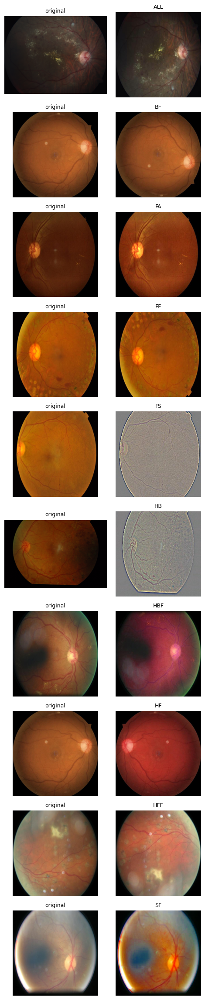


5b) Codes available for photos with no plain version (rows = code, columns = grade)
 label  Mild  Moderate  Severe  Proliferative
aug                                         
ALL       0      2130       0              0
BF        0         0       2              0
FA      711         0       0            226
FF        0         0       2              0
FS      767         0       0            243
HB      746         0       0            256
HBF       0         0       2              0
HF        0         0       2              0
HFF     746         0       2            259
SF        0         0       4              0

    Photos available ONLY as Gaussian-filtered (GF) files: 0

5c) IDRiD names used by more than one file: 22
    ...of which hold DIFFERENT images (name collision): 0
    ...of which hold the SAME image with different grades (true conflict): 22


In [7]:
# ---------- 5a. What does each augmentation code do? ----------
def load_small(path, size=128):
    return np.asarray(Image.open(path).convert('L').resize((size, size)), dtype=np.float32)

def corr(a, b):
    a = a - a.mean(); b = b - b.mean()
    return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-8))

TRANSFORMS = {                      # undo candidates: which one makes the copy match the original?
    'none':   lambda x: x,
    'hflip':  lambda x: x[:, ::-1],
    'vflip':  lambda x: x[::-1, :],
    'rot180': lambda x: x[::-1, ::-1],
    'rot90':  lambda x: np.rot90(x, 1),
    'rot270': lambda x: np.rot90(x, 3),
}

# one plain (un-augmented, not Gaussian-filtered) file per photo, to compare against
plain = df[(df.aug == 'none') & (~df.gf)].drop_duplicates('base_id').set_index('base_id')['path']

rows, examples = [], {}
for code in sorted(df.loc[df.is_aug, 'aug'].unique()):
    sub = df[(df.aug == code) & df.base_id.isin(plain.index)]
    if len(sub) == 0:
        print(f"{code}: no plain original to compare with"); continue
    sample = sub.sample(min(20, len(sub)), random_state=0)
    for _, r in sample.iterrows():
        o, a = load_small(plain[r.base_id]), load_small(r.path)
        scores = {name: corr(o, t(a)) for name, t in TRANSFORMS.items()}
        best = max(scores, key=scores.get)
        rows.append({'code': code, 'geometric': best, 'match': scores[best],
                     'brightness': a.mean() / (o.mean() + 1e-6),
                     'contrast': a.std() / (o.std() + 1e-6)})
    examples[code] = (plain[sample.iloc[0].base_id], sample.iloc[0].path)

res = pd.DataFrame(rows)
summary = res.groupby('code').agg(
    pairs=('match', 'size'),
    geometric=('geometric', lambda s: s.value_counts().index[0]),
    agreement=('geometric', lambda s: round(s.value_counts(normalize=True).iloc[0], 2)),
    match=('match', 'median'),
    brightness=('brightness', 'median'),
    contrast=('contrast', 'median'),
).round(2)
print("5a) What each code does (brightness/contrast: 1.0 = unchanged)\n", summary)

fig, axes = plt.subplots(len(examples), 2, figsize=(5, 2.3 * len(examples)))
for ax_row, (code, (po, pa)) in zip(axes, examples.items()):
    for ax, p, title in zip(ax_row, (po, pa), ('original', code)):
        im = Image.open(p).convert('RGB'); im.thumbnail((256, 256))
        ax.imshow(im); ax.set_title(title, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

# ---------- 5b. For photos that exist ONLY as copies: which codes do we have? ----------
aug_only_ids = ok.index[~ok['has_original']]
aug_only = df[df.base_id.isin(aug_only_ids)]
print("\n5b) Codes available for photos with no plain version (rows = code, columns = grade)\n",
      pd.crosstab(aug_only.aug, aug_only.label).rename(columns=CLASS_NAMES))
print("\n    Photos available ONLY as Gaussian-filtered (GF) files:", int(df.groupby('base_id')['gf'].all().sum()))

# ---------- 5c. IDRiD: same name = same image? ----------
idr = df[df.source == 'IDRiD'].copy()
idr['md5'] = idr['path'].apply(lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest())
g = idr.groupby('base_id').agg(files=('md5', 'size'), different_images=('md5', 'nunique'),
                               grades=('label', lambda s: sorted(set(s))))
print("\n5c) IDRiD names used by more than one file:", (g.files > 1).sum())
print("    ...of which hold DIFFERENT images (name collision):", (g.different_images > 1).sum())
print("    ...of which hold the SAME image with different grades (true conflict):",
      ((g.different_images == 1) & (g.grades.apply(len) > 1)).sum())

## Step 6 · Check every file for the "processed" look
Measures every image: corner brightness (grey vs black background), saturation, and red/green balance.

**Results**
- **Solid:** the grey look is **not** caused by the augmentation codes. 100% of `GF` (Gaussian-filtered APTOS) files are grey, versus 0.1% of plain originals; the grey copies were made from `GF` images. All `GF` and grey files are excluded.
- The first selection rule (v1) applied here is superseded (see Steps 8–10).

In [8]:
def look_stats(path):
    im = Image.open(path); im.draft('RGB', (256, 256))
    im = im.convert('RGB').resize((128, 128))
    a = np.asarray(im, dtype=np.float32); gray = a.mean(2)
    corners = np.concatenate([gray[:10, :10].ravel(), gray[:10, -10:].ravel(),
                              gray[-10:, :10].ravel(), gray[-10:, -10:].ravel()])
    hsv = np.asarray(im.convert('HSV'), dtype=np.float32)[32:96, 32:96]
    c = a[32:96, 32:96]
    return corners.mean(), hsv[..., 1].mean(), c[..., 0].mean() / (c[..., 1].mean() + 1)

with ThreadPoolExecutor(8) as ex:
    stats = list(ex.map(look_stats, df['path']))
df[['corner_bg', 'saturation', 'red_green']] = pd.DataFrame(stats, index=df.index)
df['processed'] = df['corner_bg'] > 60          # grey background instead of black = heavily processed
df.to_csv(os.path.join(PROJECT_DIR, 'index.csv'), index=False)

print("6a) Fraction of files with the grey 'processed' look, per code\n",
      df.groupby('aug')['processed'].mean().round(3).to_string())
print("\n    Plain files: non-GF processed =", round(df[(df.aug == 'none') & ~df.gf]['processed'].mean(), 3),
      "| GF processed =", round(df[(df.aug == 'none') & df.gf]['processed'].mean(), 3))

# ---------- selection rule v1 (superseded: see Steps 8-10) ----------
PRIORITY = ['none', 'FF', 'HFF', 'HB', 'FS', 'SF']          # least altered first
EXCLUDED_SOURCES = ['IDRiD', 'Messidor-1', 'Messidor-2']   # IDRiD: bad labels; Messidor: external test

cand = df[df.aug.isin(PRIORITY) & ~df.gf & ~df.processed & ~df.source.isin(EXCLUDED_SOURCES)].copy()
cand['rank'] = cand['aug'].map({c: i for i, c in enumerate(PRIORITY)})
chosen = cand.sort_values(['base_id', 'rank']).drop_duplicates('base_id')

print("\n6b) Clean dataset preview: one file per photo (rows = which version was kept)\n",
      pd.crosstab(chosen['aug'], chosen['label'], margins=True).rename(columns=CLASS_NAMES))

lost = set(df.loc[~df.source.isin(EXCLUDED_SOURCES), 'base_id']) - set(chosen['base_id'])
print("\n    Photos with no acceptable version (dropped), by grade:\n",
      df[df.base_id.isin(lost)].drop_duplicates('base_id').groupby('label').size().rename(CLASS_NAMES).to_string())

# ---------- shortcut check: do kept copies look different from real originals? ----------
chosen['kind'] = np.where(chosen['aug'] == 'none', 'original', 'kept copy')
print("\n6c) Median look of kept files, by grade and kind\n",
      chosen.groupby(['label', 'kind'])[['saturation', 'red_green', 'corner_bg']].median().round(2)
            .rename(index=CLASS_NAMES, level=0))

chosen.to_csv(os.path.join(PROJECT_DIR, 'chosen_files_preview.csv'), index=False)

6a) Fraction of files with the grey 'processed' look, per code
 aug
ALL     0.062
BF      0.150
FA      0.116
FF      0.151
FS      0.103
HB      0.098
HBF     0.151
HF      0.151
HFF     0.112
SF      0.151
none    0.037

    Plain files: non-GF processed = 0.001 | GF processed = 1.0

6b) Clean dataset preview: one file per photo (rows = which version was kept)
 label  No DR  Mild  Moderate  Severe  Proliferative    All
aug                                                       
FF         0     0         0       2              0      2
FS         0   255         0       0             13    268
HB         0   431         0       0             39    470
HFF        0   746         0       0            259   1005
SF         0     0         0       2              0      2
none    9561  2007      5296    1119           2165  20148
All     9561  3439      5296    1123           2476  21895

    Photos with no acceptable version (dropped), by grade:
 label
Mild              141
Moderate      

## Step 7 · Compare each copy with its own original (saturation and colour)
For every copy that still has its original, measures how much saturation and red/green balance changed, and compares that with how much real photos naturally differ (7b). 7c shows 12 random `ALL`-only photos.

**Results**
- `FS`/`SF` push saturation and redness up in **every** copy (a systematic shift).
- `HB`, `HBF`, `HF`, `HFF`, `ALL` shift colour randomly in both directions.
- This measured only two properties and had no pre-set criterion. Step 9 repeats it properly.

7a) Change caused by each code (median, and the middle-50% range)
    d_saturation               d_red_green            
            0.25   0.50   0.75        0.25  0.50  0.75
aug                                                   
ALL        -0.19  -0.01   0.24       -0.29 -0.02  0.37
BF         -0.02   0.00   0.15        0.00  0.00  0.00
FA        -19.25  -6.92  -1.73       -0.25 -0.11 -0.03
FF         -0.06   0.00   0.14        0.00  0.00  0.00
FS         30.03  65.62  95.29        0.22  0.47  0.80
HB         -0.18   0.01   0.26       -0.27  0.02  0.42
HBF        -0.16   0.02   0.26       -0.29 -0.00  0.45
HF         -0.16   0.00   0.24       -0.31 -0.02  0.43
HFF        -0.17   0.02   0.28       -0.28  0.02  0.43
SF         34.70  67.89  97.79        0.23  0.51  0.75

7b) Natural spread among real originals (middle-50% range width):
    saturation: 90.44 | red_green: 0.52


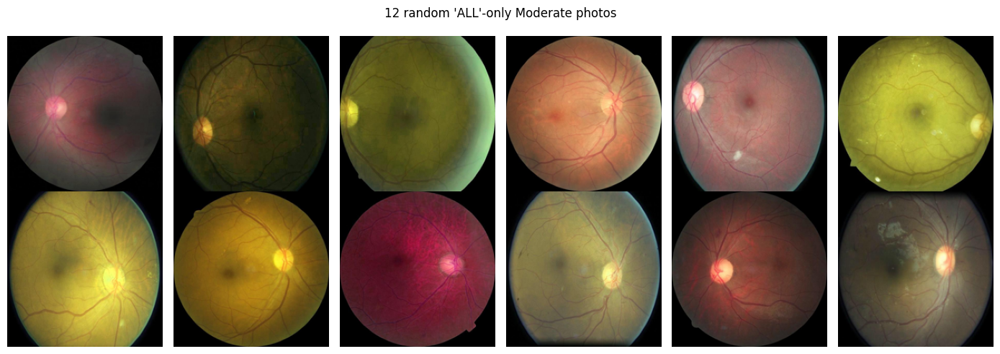

In [9]:
# 7a. How much does each code change a photo's look? (copy minus ITS OWN original)
orig = (df[(df.aug == 'none') & ~df.gf & ~df.processed]
        .drop_duplicates('base_id').set_index('base_id')[['saturation', 'red_green']])
pairs = df[df.is_aug & ~df.gf & ~df.processed & df.base_id.isin(orig.index)].copy()
pairs['d_saturation'] = pairs['saturation'].values - orig.loc[pairs['base_id'], 'saturation'].values
pairs['d_red_green'] = pairs['red_green'].values - orig.loc[pairs['base_id'], 'red_green'].values

print("7a) Change caused by each code (median, and the middle-50% range)")
print(pairs.groupby('aug')[['d_saturation', 'd_red_green']]
      .quantile([0.25, 0.5, 0.75]).unstack().round(2).to_string())

# 7b. How much do REAL photos naturally differ? (spread among originals)
o = df[(df.aug == 'none') & ~df.gf & ~df.processed]
print("\n7b) Natural spread among real originals (middle-50% range width):")
print("    saturation:", round(o.saturation.quantile(.75) - o.saturation.quantile(.25), 2),
      "| red_green:", round(o.red_green.quantile(.75) - o.red_green.quantile(.25), 2))

# 7c. Look at 12 random 'ALL'-only Moderate photos: is the red cast typical or rare?
all_only = df[(df.aug == 'ALL') & df.base_id.isin(lost) & ~df.processed].drop_duplicates('base_id')
s = all_only.sample(min(12, len(all_only)), random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, p in zip(axes.ravel(), s['path']):
    im = Image.open(p).convert('RGB'); im.thumbnail((200, 200)); ax.imshow(im); ax.axis('off')
fig.suptitle("12 random 'ALL'-only Moderate photos"); plt.tight_layout(); plt.show()

## Step 8 · Selection rule v2 (superseded by v3, Step 10)
Keeps one file per photo (original first, then copies), drops IDRiD, Messidor, `GF` and grey files, and marks copies and their patients as **train only**.

v2 counted the random-hue copies (`HB`, `HBF`, `HF`, `HFF`, `ALL`) as part of the dataset: 23,755 photos. Step 9 showed most of those copies change colour far beyond normal augmentation, so in **v3** they're no longer part of the base dataset (Step 10). The `clean` table built here is still used by Step 10.

In [10]:
PRIORITY_V2 = ['none', 'FF', 'BF', 'HFF', 'HB', 'HF', 'HBF', 'ALL']   # geometry-only first, then random jitter
EXCLUDED_SOURCES = ['IDRiD', 'Messidor-1', 'Messidor-2']

cand = df[df.aug.isin(PRIORITY_V2) & ~df.gf & ~df.processed & ~df.source.isin(EXCLUDED_SOURCES)].copy()
cand['rank'] = cand['aug'].map({c: i for i, c in enumerate(PRIORITY_V2)})
clean = cand.sort_values(['base_id', 'rank']).drop_duplicates('base_id').copy()
clean['is_copy'] = clean['aug'] != 'none'

print("8a) Clean dataset v2: one file per photo\n",
      pd.crosstab(clean['is_copy'], clean['label'], margins=True).rename(columns=CLASS_NAMES))

dropped = set(df.loc[~df.source.isin(EXCLUDED_SOURCES), 'base_id']) - set(clean['base_id'])
print("\n8b) Photos with no acceptable version (dropped), by grade:\n",
      df[df.base_id.isin(dropped)].drop_duplicates('base_id').groupby('label').size().rename(CLASS_NAMES).to_string())

# copies must stay in train, and so must the other eye of the same EyePACS patient
clean['patient'] = np.where(clean['source'] == 'EyePACS',
                            'eyepacs_' + clean['base_id'].str.split('_').str[0], clean['base_id'])
copy_patients = set(clean.loc[clean['is_copy'], 'patient'])
clean['train_only'] = clean['patient'].isin(copy_patients)

print("\n8c) Photos forced into train (a copy, or same patient as a copy):", int(clean['train_only'].sum()))
print("    Photos free to split into train / val / test, by grade:\n",
      clean[~clean['train_only']].groupby('label').size().rename(CLASS_NAMES).to_string())

clean.to_csv(os.path.join(PROJECT_DIR, 'clean_photos_v2.csv'), index=False)

8a) Clean dataset v2: one file per photo
 label    No DR  Mild  Moderate  Severe  Proliferative    All
is_copy                                                     
False     9561  2007      5296    1119           2165  20148
True         0  1177      2130       2            298   3607
All       9561  3184      7426    1121           2463  23755

8b) Photos with no acceptable version (dropped), by grade:
 label
Mild             396
Moderate           1
Severe             2
Proliferative     25

8c) Photos forced into train (a copy, or same patient as a copy): 4470
    Photos free to split into train / val / test, by grade:
 label
No DR            9491
Mild             1806
Moderate         4903
Severe           1089
Proliferative    1996


## Step 9 · Measure every copy against its original
For **all** ~14,100 copies that still have their original, we measure: which flip undoes the copy, and how brightness, contrast, saturation, red/green balance and zoom changed (1.00 = unchanged).

The **acceptance envelope was fixed before looking at the results**, so it can't be bent to fit them. It matches typical training colour augmentation: brightness/contrast/saturation ×0.80–1.25, red/green ×0.90–1.10, zoom ×0.95–1.05. 9c shows 6 random pairs per code, marked ✓/✗.

*(This step needs the Step 2 cell to use `sorted(os.listdir(...))`, so every run gives identical results.)*

**Results: four families**

| Family | Codes | Effect (median [5th–95th %]) | Inside envelope |
|---|---|---|---|
| A: geometry only | `FF`, `BF` | Flips; colour unchanged (red/green 1.00 [1.00–1.01]) | 90% ✅ |
| B: random hue shift | `HB`, `HBF`, `HF`, `HFF`, `ALL` | Flips + large random hue shift (red/green 0.99 [0.60–2.18]) | 22–26% ❌ |
| C: darker + oversaturated | `FS`, `SF` | Darker ×0.83, saturation ×1.47, redder | 12–14% ❌ |
| D: strong brightening | `FA` | Brightness ×1.60 [1.41–2.53] | 0% ❌ |

- No code crops, zooms or rotates by odd angles.
- **Limitation:** brightness ratios exaggerate changes in very dark photos.

9a) Change caused by each code, ALL pairs (1.00 = unchanged; median [5th–95th percentile])
      pairs                                   geometric  match_p5        brightness          contrast        saturation         red_green              zoom
code                                                                                                                                                       
ALL    1132  hflip 27%, rot180 25%, none 25%, vflip 23%      0.99  1.03 [0.86–1.35]  1.03 [0.85–1.44]  1.00 [0.99–1.01]  0.99 [0.60–2.18]  1.00 [1.00–1.01]
BF      845                         vflip 51%, none 49%      1.00  1.00 [1.00–1.34]  1.00 [1.00–1.44]  1.00 [0.99–1.00]  1.00 [1.00–1.01]  1.00 [1.00–1.01]
FA     2588                         vflip 50%, none 50%      0.97  1.60 [1.41–2.53]  1.44 [1.09–2.34]  0.97 [0.70–1.00]  0.97 [0.78–1.01]  1.00 [1.00–1.02]
FF      844  none 27%, hflip 25%, vflip 25%, rot180 24%      1.00  1.00 [1.00–1.34]  1.00 [1.00–1.44]  1.00 [0.99–1.00]  1.00 [1.

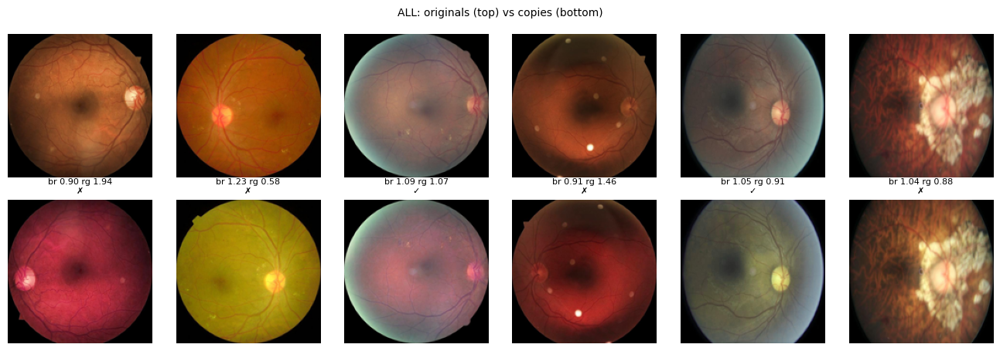

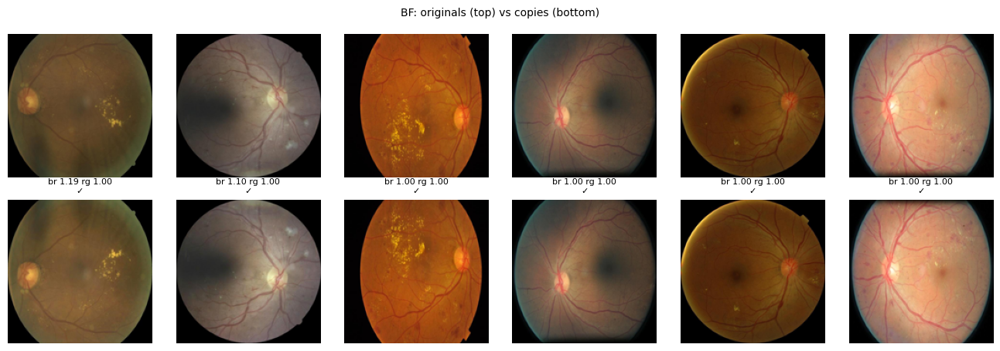

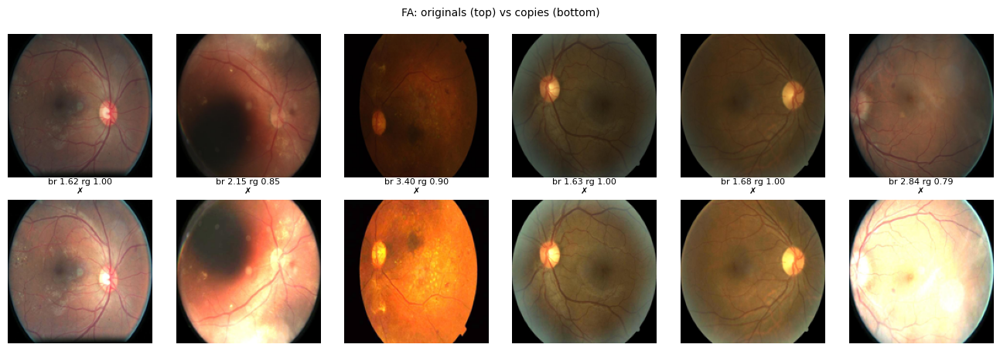

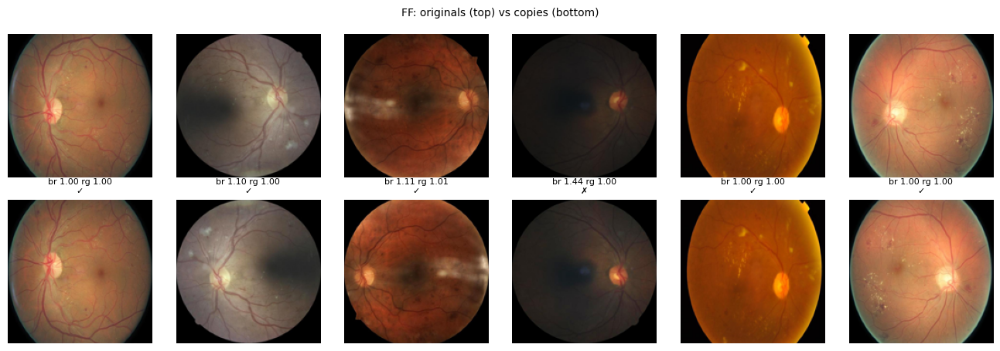

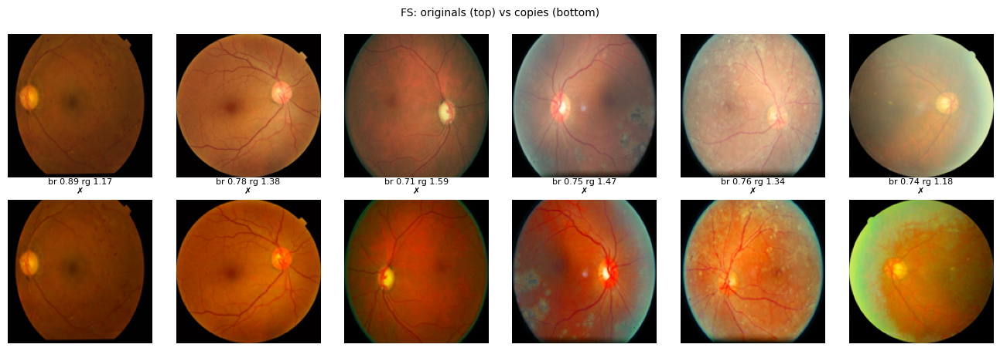

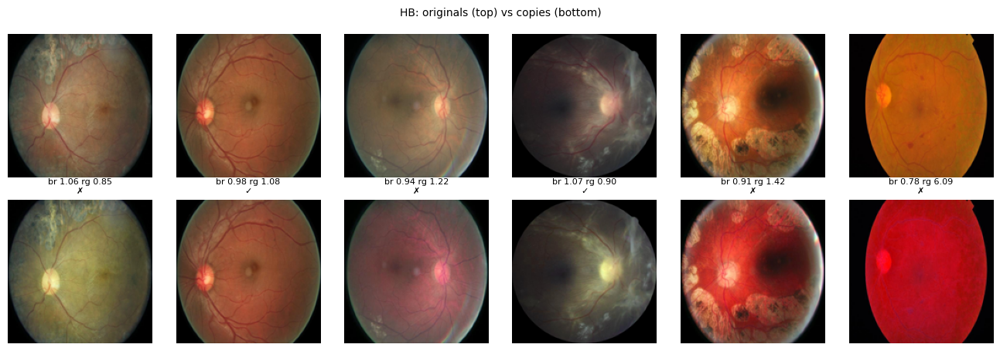

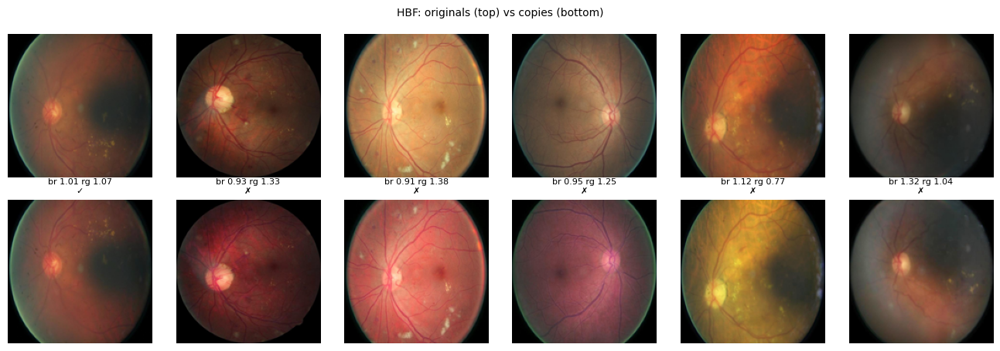

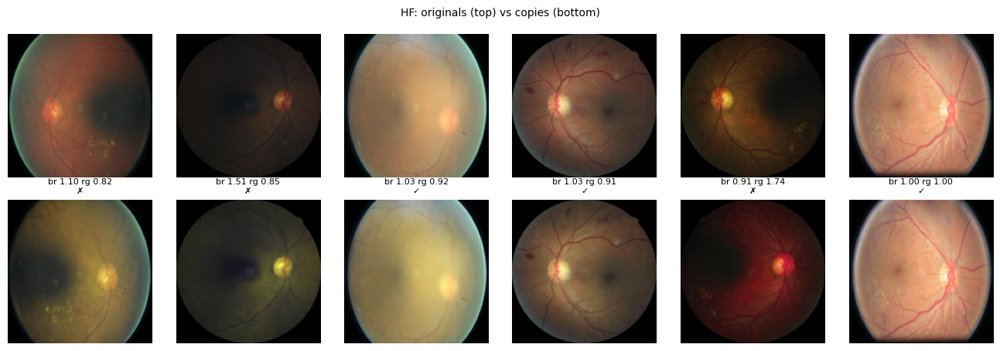

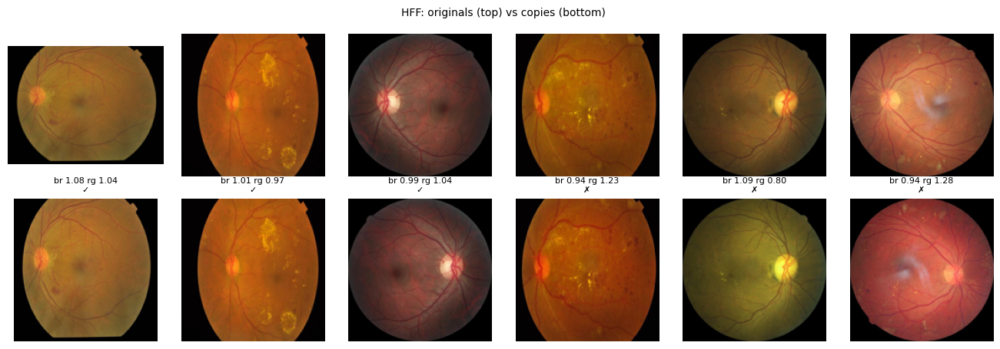

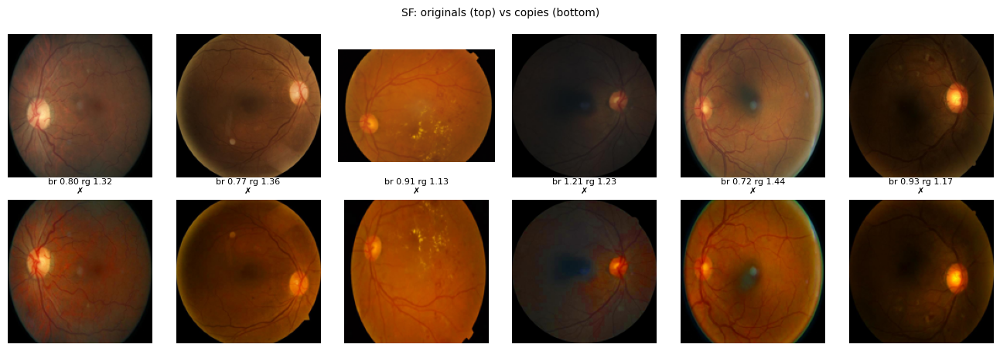

In [11]:
def small_rgb(path, size=128):
    im = Image.open(path); im.draft('RGB', (256, 256))
    return np.asarray(im.convert('RGB').resize((size, size)), dtype=np.float32)

def measures(a):
    gray = a.mean(2); mask = gray > 20
    inside = mask if mask.sum() > 100 else np.ones_like(mask)
    hsv = np.asarray(Image.fromarray(a.astype(np.uint8)).convert('HSV'), dtype=np.float32)
    cols = np.where(mask.mean(0) > 0.05)[0]
    return dict(brightness=gray[inside].mean(), contrast=gray[inside].std(),
                saturation=hsv[..., 1][inside].mean(),
                red_green=a[..., 0][inside].mean() / (a[..., 1][inside].mean() + 1),
                fundus_width=(cols[-1] - cols[0] + 1) / a.shape[1] if len(cols) else np.nan)

def pair_measure(job):
    po, pa = job
    o, a = small_rgb(po), small_rgb(pa)
    scores = {n: corr(o.mean(2), t(a.mean(2))) for n, t in TRANSFORMS.items()}
    best = max(scores, key=scores.get)
    mo, ma = measures(o), measures(a)
    ratio = lambda k: ma[k] / (mo[k] + 1e-6)          # 1.0 = unchanged
    return dict(geometric=best, match=scores[best], brightness=ratio('brightness'),
                contrast=ratio('contrast'), saturation=ratio('saturation'),
                red_green=ratio('red_green'), zoom=ratio('fundus_width'))

# every copy that still has a plain, non-GF, non-grey original
plain = (df[(df.aug == 'none') & ~df.gf & ~df.processed]
         .sort_values('path').drop_duplicates('base_id').set_index('base_id')['path'])
copies = df[df.is_aug & ~df.gf & ~df.processed & df.base_id.isin(plain.index)].sort_values('path')
jobs = list(zip(plain.loc[copies['base_id']].values, copies['path'].values))
with ThreadPoolExecutor(8) as ex:
    out = list(ex.map(pair_measure, jobs))
P = pd.concat([copies[['base_id', 'aug', 'label', 'source']].reset_index(drop=True), pd.DataFrame(out)], axis=1)
P.to_csv(os.path.join(PROJECT_DIR, 'pair_measures.csv'), index=False)

# 9a. full picture per code: median [5th–95th percentile]
rows = []
for code, g in P.groupby('aug'):
    row = {'code': code, 'pairs': len(g),
           'geometric': ', '.join(f"{k} {v:.0%}" for k, v in g['geometric'].value_counts(normalize=True).items()),
           'match_p5': round(g['match'].quantile(.05), 2)}
    for m in ['brightness', 'contrast', 'saturation', 'red_green', 'zoom']:
        row[m] = f"{g[m].median():.2f} [{g[m].quantile(.05):.2f}–{g[m].quantile(.95):.2f}]"
    rows.append(row)
print("9a) Change caused by each code, ALL pairs (1.00 = unchanged; median [5th–95th percentile])")
print(pd.DataFrame(rows).set_index('code').to_string())

# 9b. criterion fixed in advance: within the colour augmentation we'll apply to EVERY training image
ENVELOPE = {'brightness': (0.80, 1.25), 'contrast': (0.80, 1.25), 'saturation': (0.80, 1.25),
            'red_green': (0.90, 1.10), 'zoom': (0.95, 1.05)}
for m, (lo, hi) in ENVELOPE.items():
    P[f'ok_{m}'] = P[m].between(lo, hi)
P['within_envelope'] = P[[f'ok_{m}' for m in ENVELOPE]].all(axis=1)
print("\n9b) % of copies inside the envelope, overall and per measure")
print((P.groupby('aug')[['within_envelope'] + [f'ok_{m}' for m in ENVELOPE]].mean() * 100).round(0).to_string())

# 9c. visual check: 6 random pairs per code (fixed seed)
for code, g in P.groupby('aug'):
    s = g.sample(min(6, len(g)), random_state=SEED)
    fig, axes = plt.subplots(2, len(s), figsize=(2.2 * len(s), 4.6))
    for j, (_, r) in enumerate(s.iterrows()):
        for i, p in enumerate((plain[r.base_id], copies.loc[copies.base_id.eq(r.base_id) & copies.aug.eq(code), 'path'].iloc[0])):
            im = Image.open(p).convert('RGB'); im.thumbnail((160, 160))
            axes[i, j].imshow(im); axes[i, j].axis('off')
        axes[1, j].set_title(f"br {r.brightness:.2f} rg {r.red_green:.2f}\n{'✓' if r.within_envelope else '✗'}", fontsize=8)
    fig.suptitle(f"{code}: originals (top) vs copies (bottom)", fontsize=10)
    plt.tight_layout(); plt.show()

## Step 10 · Base dataset vs optional add-on, and a question about DDR labels
**10a. Selection rule v3:** base dataset = originals + family A; family B copies are a flagged, train-only add-on.

| | No DR | Mild | Moderate | Severe | PDR | Total |
|---|---|---|---|---|---|---|
| Base dataset | 9,561 | 2,007 | 5,296 | 1,121 | 2,165 | 20,150 |
| Add-on (family B, train only) | 0 | 1,177 | 2,130 | 0 | 298 | 3,605 |

**10b–c.** For `nnn-nnnn-nnn` files, the last number in the name disagreed with the folder label 30% of the time, in a systematic pattern. The images alone can't tell which is right. **Answered in Step 11.**

10a) Kept files by family and grade
 label       No DR  Mild  Moderate  Severe  Proliferative    All
family                                                         
A_geometry      0     0         0       2              0      2
B_hue           0  1177      2130       0            298   3605
original     9561  2007      5296    1119           2165  20148
All          9561  3184      7426    1121           2463  23755

    BASE dataset (originals + family A): 20150
    {'No DR': 9561, 'Mild': 2007, 'Moderate': 5296, 'Severe': 1121, 'Proliferative': 2165}
    Optional ADD-ON (family B copies, train only): 3605
    {'Mild': 1177, 'Moderate': 2130, 'Proliferative': 298}

10b) nnn-nnnn-ggg: code in name (rows) vs folder label (columns)
 label          No DR  Mild  Moderate  Severe  Proliferative   All
grade_in_name                                                    
0.0              345    10        12       1              0   368
1.0               44   248       192       2              1 

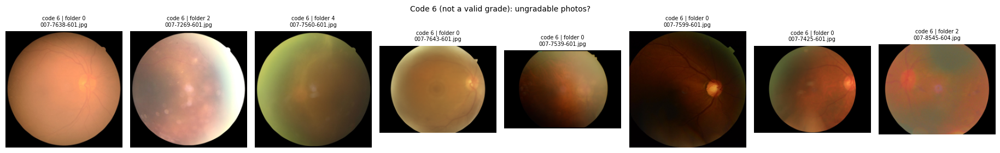

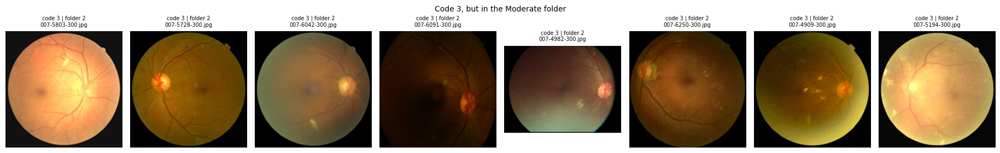

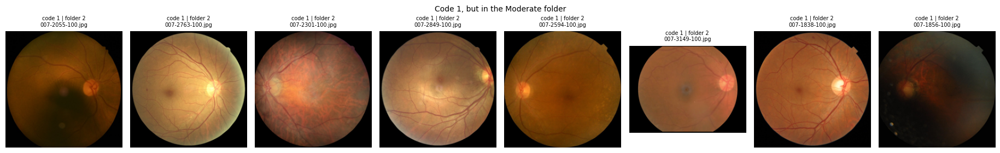

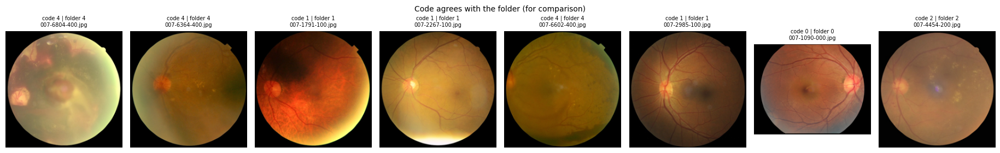

In [12]:
# 10a. Families and exact counts (uses `clean` from Step 8)
FAMILY = {'none': 'original', 'FF': 'A_geometry', 'BF': 'A_geometry',
          'HB': 'B_hue', 'HBF': 'B_hue', 'HF': 'B_hue', 'HFF': 'B_hue', 'ALL': 'B_hue',
          'FS': 'C_dark_saturated', 'SF': 'C_dark_saturated', 'FA': 'D_bright'}
clean['family'] = clean['aug'].map(FAMILY)
print("10a) Kept files by family and grade\n",
      pd.crosstab(clean['family'], clean['label'], margins=True).rename(columns=CLASS_NAMES))
base = clean[clean['family'].isin(['original', 'A_geometry'])]
addon = clean[clean['family'] == 'B_hue']
print("\n    BASE dataset (originals + family A):", len(base))
print("   ", base.groupby('label').size().rename(CLASS_NAMES).to_dict())
print("    Optional ADD-ON (family B copies, train only):", len(addon))
print("   ", addon.groupby('label').size().rename(CLASS_NAMES).to_dict())

# 10b. nnn-nnnn-ggg (DDR): the number in the name vs the folder label.
#      Step 11 shows this number is NOT a grade; the folder labels are correct.
nnn = clean[clean['source'] == 'nnn-nnnn-ggg'].copy()
print("\n10b) nnn-nnnn-ggg: code in name (rows) vs folder label (columns)\n",
      pd.crosstab(nnn['grade_in_name'], nnn['label'], margins=True).rename(columns=CLASS_NAMES))
nnn['agree'] = nnn['grade_in_name'] == nnn['label']
print("\n    Agreement by folder label (%):",
      (nnn.groupby('label')['agree'].mean() * 100).round(1).rename(CLASS_NAMES).to_dict())
print("    Overall agreement:", round(nnn['agree'].mean() * 100, 1), "%")

# 10c. What do the suspicious ones look like? (fixed seed)
def grid(sub, title, n=8):
    s = sub.sample(min(n, len(sub)), random_state=SEED)
    if len(s) == 0: print(title, ": none"); return
    fig, axes = plt.subplots(1, len(s), figsize=(2.3 * len(s), 2.9))
    for ax, (_, r) in zip(np.atleast_1d(axes), s.iterrows()):
        im = Image.open(r['path']).convert('RGB'); im.thumbnail((200, 200))
        ax.imshow(im); ax.axis('off')
        ax.set_title(f"code {r['grade_in_name']:.0f} | folder {r['label']}\n{r['fname'][:18]}", fontsize=7)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

grid(nnn[nnn['grade_in_name'] == 6], "Code 6 (not a valid grade): ungradable photos?")
grid(nnn[(nnn['grade_in_name'] == 3) & (nnn['label'] == 2)], "Code 3, but in the Moderate folder")
grid(nnn[(nnn['grade_in_name'] == 1) & (nnn['label'] == 2)], "Code 1, but in the Moderate folder")
grid(nnn[nnn['agree']], "Code agrees with the folder (for comparison)")

## Step 11 · Check DDR files against DDR's official labels
Downloads DDR's official label files (`train/valid/test.txt`) from **two independent mirrors** and checks they agree.

**Results**
- The mirrors agree on **100%** of 13,673 labels.
- **Both** unusual name patterns (`nnn-nnnn-nnn` and 17-digit timestamps) are **DDR**: 100% found.
- **Folder label = official label: 100%.** The number in the name matches only 69.6%, so it is **not** a grade, and the folders are right.
- None of our DDR files is officially "ungradable". All 236 official DDR Severe images are included.

In [13]:
MIRRORS = {   # community copies of DDR on Hugging Face; we check they agree with each other
    'YBoWen':    'https://huggingface.co/datasets/YBoWen/DDR-dataset/resolve/main/DR_grading/{}.txt',
    'ctmedtech': 'https://huggingface.co/datasets/ctmedtech/DDR-dataset/resolve/main/DR_grading/{}.txt',
}

def load_ddr_labels(url_template):
    parts = []
    for split in ['train', 'valid', 'test']:
        r = requests.get(url_template.format(split), timeout=60); r.raise_for_status()
        t = pd.read_csv(io.StringIO(r.text), sep=r'\s+', header=None, names=['ddr_name', 'ddr_label'])
        t['ddr_split'] = split; parts.append(t)
    out = pd.concat(parts, ignore_index=True)
    out['ddr_stem'] = out['ddr_name'].str.replace(r'\.\w+$', '', regex=True)
    return out

labels = {}
for name, tpl in MIRRORS.items():
    try:
        labels[name] = load_ddr_labels(tpl); print(f"{name}: {len(labels[name])} labelled images")
    except Exception as e:
        print(f"{name}: could not load ({e})")

if len(labels) == 2:
    a, b = labels.values()
    both = a.merge(b, on='ddr_stem', suffixes=('_1', '_2'))
    print("Mirrors agree on", f"{(both.ddr_label_1 == both.ddr_label_2).mean():.2%}", "of", len(both), "shared images")

ddr = next(iter(labels.values()))
print("\n11a) Official DDR label counts (expect 0–4 plus 5 = ungradable):\n",
      ddr['ddr_label'].value_counts().sort_index().to_string())

# match our files to the official list (full DDR name = all three number groups)
x = df[df.source.isin(['nnn-nnnn-ggg', 'timestamp'])].copy()
x['ddr_stem'] = x['fname'].str.extract(r'^(\d{3}-\d{4}-\d{3}|\d{14,})')[0]
m = x.merge(ddr[['ddr_stem', 'ddr_label', 'ddr_split']], on='ddr_stem', how='left')
print("\n11b) Share of our files found in the official DDR grading list, by source:")
print(m.groupby('source')['ddr_label'].apply(lambda s: f"{s.notna().mean():.1%}").to_string())

mm = m[(m.source == 'nnn-nnnn-ggg') & m.ddr_label.notna()].drop_duplicates('base_id')
print("\n11c) Official DDR label (rows) vs the CODE in the filename (columns)\n",
      pd.crosstab(mm['ddr_label'], mm['grade_in_name']))
print("\n11d) Official DDR label (rows) vs the FOLDER label (columns)\n",
      pd.crosstab(mm['ddr_label'], mm['label']).rename(columns=CLASS_NAMES))
print("\n    Code matches official:  ", f"{(mm.ddr_label == mm.grade_in_name).mean():.1%}")
print("    Folder matches official:", f"{(mm.ddr_label == mm.label).mean():.1%}")

YBoWen: 13673 labelled images
ctmedtech: 13673 labelled images
Mirrors agree on 100.00% of 13673 shared images

11a) Official DDR label counts (expect 0–4 plus 5 = ungradable):
 ddr_label
0    6266
1     630
2    4477
3     236
4     913
5    1151

11b) Share of our files found in the official DDR grading list, by source:
source
nnn-nnnn-ggg    100.0%
timestamp       100.0%

11c) Official DDR label (rows) vs the CODE in the filename (columns)
 grade_in_name  0.0  1.0  2.0  3.0  4.0  6.0
ddr_label                                  
0              345   44    0    2    0   34
1               10  248    1    0    0    0
2               12  192  432  383    3   37
3                1    2   55  130    7    0
4                0    1    8    5  693   10

11d) Official DDR label (rows) vs the FOLDER label (columns)
 label      No DR  Mild  Moderate  Severe  Proliferative
ddr_label                                              
0            425     0         0       0              0
1            

## Step 12 · Check APTOS and EyePACS against their official labels
**Before running:** while signed in to Kaggle, accept the rules of both competitions (`diabetic-retinopathy-detection` and `aptos2019-blindness-detection`). The cell downloads **only the label files**, never the image archives.

**Results**
- **12a:** DDR timestamp files: folder = official **100%**, 0 ungradable.
- **APTOS:** 3,662 / 3,662 photos found; folder = official **100%**.
- **EyePACS:** only 45.8% of our photos are in the competition's *train* labels (all 100% correct). The rest must come from its *test* set (Step 12d).

In [14]:
# 12a. DDR timestamp files: folder vs official, and any officially ungradable files
t = m[(m.source == 'timestamp') & m.ddr_label.notna()].drop_duplicates('base_id')
print("12a) DDR timestamp files: official (rows) vs folder (columns)\n",
      pd.crosstab(t['ddr_label'], t['label']).rename(columns=CLASS_NAMES))
print("    Folder matches official:", f"{(t.ddr_label == t.label).mean():.1%}",
      "| our DDR files officially 'ungradable' (5):", int((m.ddr_label == 5).sum()))

# 12b. download ONLY the label files of the original competitions
assert 'path' in inspect.signature(kagglehub.competition_download).parameters, \
    "This kagglehub version can't download single files. Update it first: !pip install -U kagglehub"

def get_label_file(competition, filename):
    try:
        p = kagglehub.competition_download(competition, path=filename)
        if p.endswith('.zip'):
            with zipfile.ZipFile(p) as z:
                z.extractall(os.path.dirname(p))
                p = os.path.join(os.path.dirname(p), z.namelist()[0])
        print(f"   {competition}/{filename} -> OK")
        return pd.read_csv(p)
    except Exception as e:
        print(f"   {competition}/{filename} -> failed: {str(e)[:150]}")
        return None

print("\n12b) Downloading official label files")
aptos_off = get_label_file('aptos2019-blindness-detection', 'train.csv')
eyepacs_train = get_label_file('diabetic-retinopathy-detection', 'trainLabels.csv.zip')
eyepacs_test = get_label_file('diabetic-retinopathy-detection', 'retinopathy_solution.csv')

# 12c. compare photo by photo (uses `ok` from Step 4: one row per photo, with its folder label)
def compare(official, id_col, label_col, source):
    o = official.rename(columns={id_col: 'base_id', label_col: 'official'})[['base_id', 'official']]
    ours = ok[ok['source'] == source][['label']].reset_index()
    j = ours.merge(o.drop_duplicates('base_id'), on='base_id', how='left')
    found = j['official'].notna()
    print(f"\n12c) {source}: {found.mean():.1%} of our {len(j)} photos found in the official labels")
    jj = j[found]
    print("    official (rows) vs folder (columns)\n",
          pd.crosstab(jj['official'].astype(int), jj['label']).rename(columns=CLASS_NAMES))
    print("    Folder matches official:", f"{(jj['official'] == jj['label']).mean():.2%}")
    return j

if aptos_off is not None:
    aptos_check = compare(aptos_off, 'id_code', 'diagnosis', 'APTOS')
eyepacs_parts = [d for d in (eyepacs_train, eyepacs_test) if d is not None]
if eyepacs_parts:
    eyepacs_off = pd.concat([d[['image', 'level']] for d in eyepacs_parts], ignore_index=True)
    eyepacs_check = compare(eyepacs_off, 'image', 'level', 'EyePACS')

12a) DDR timestamp files: official (rows) vs folder (columns)
 label      No DR  Mild  Moderate  Severe  Proliferative
ddr_label                                              
0           1053     0         0       0              0
1              0    16         0       0              0
2              0     0       250       0              0
3              0     0         0      41              0
4              0     0         0       0              1
    Folder matches official: 100.0% | our DDR files officially 'ungradable' (5): 0

12b) Downloading official label files


100%|██████████| 53.7k/53.7k [00:00<00:00, 890kB/s]

   aptos2019-blindness-detection/train.csv -> OK


100%|██████████| 69.4k/69.4k [00:00<00:00, 259kB/s]


   diabetic-retinopathy-detection/trainLabels.csv.zip -> OK
   diabetic-retinopathy-detection/retinopathy_solution.csv -> failed: 404 Client Error.

Resource not found at URL: https://kaggle.com/competitions/diabetic-retinopathy-detection
Please make sure you specified the correc

12c) APTOS: 100.0% of our 3662 photos found in the official labels
    official (rows) vs folder (columns)
 label     No DR  Mild  Moderate  Severe  Proliferative
official                                              
0          1805     0         0       0              0
1             0   370         0       0              0
2             0     0       999       0              0
3             0     0         0     193              0
4             0     0         0       0            295
    Folder matches official: 100.00%

12c) EyePACS: 45.8% of our 16501 photos found in the official labels
    official (rows) vs folder (columns)
 label     No DR  Mild  Moderate  Severe  Proliferative
official              

### 12d. EyePACS test-set labels
The test-set labels were published separately after the competition. Instead of guessing the file's address, we read it from the source code of TensorFlow Datasets' EyePACS loader. TFDS comes pre-installed in Colab, which is why the cell prints a long list of addresses.

**Results**
- 53,576 test labels loaded. No image appears in both the train and test label files.
- **EyePACS: 16,501 / 16,501 photos found; folder = official 100%.**
- ➜ Every label in our training pool is verified against its original source (D-011).

In [ ]:
import tensorflow_datasets as tfds      # only needed here; pre-installed in Colab

# 1. find the label-file address inside TFDS's EyePACS loader (no guessing)
tfds_dir = os.path.dirname(tfds.__file__)
urls = set()
for root, _, files in os.walk(tfds_dir):
    if 'diabetic_retinopathy' in root or any('diabetic_retinopathy' in f for f in files):
        for f in files:
            if f.endswith('.py'):
                urls |= set(re.findall(r'https?://[^\s"\'\)]+', open(os.path.join(root, f), encoding='utf-8').read()))
print("12d) Addresses found in the TFDS EyePACS loader:")
for u in sorted(urls): print("   ", u)

label_urls = [u for u in urls if u.lower().endswith('.csv') or 'solution' in u.lower()]
eyepacs_test = None
for u in label_urls:
    try:
        r = requests.get(u, timeout=60); r.raise_for_status()
        eyepacs_test = pd.read_csv(io.StringIO(r.text))
        print(f"\n    Loaded {len(eyepacs_test)} rows from {u}\n    columns: {list(eyepacs_test.columns)}")
        break
    except Exception as e:
        print(f"    {u} -> failed: {str(e)[:120]}")

# 2. compare: train labels + test labels together
if eyepacs_test is not None:
    eyepacs_off = pd.concat([eyepacs_train[['image', 'level']], eyepacs_test[['image', 'level']]],
                            ignore_index=True)
    print("    Same image in both official files?", eyepacs_off['image'].duplicated().sum())
    eyepacs_check = compare(eyepacs_off, 'image', 'level', 'EyePACS')

12d) Addresses found in the TFDS EyePACS loader:
    http://ai.stanford.edu/~jkrause/car196/
    http://arxiv.org/abs/1703.10593},
    http://arxiv.org/abs/1708.07747},
    http://arxiv.org/abs/1708.09427
    http://arxiv.org/abs/1708.09427},
    http://arxiv.org/abs/1901.07031},
    http://codh.rois.ac.jp/kmnist/dataset/kmnist/
    http://codh.rois.ac.jp/kmnist/index.html.en
    http://creativecommons.org/licenses/by/4.0
    http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
    http://dx.doi.org/10.1016/j.asoc.2011.11.030},
    http://dx.doi.org/10.1016/j.asoc.2012.03.039},
    http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/
    http://laurencemoroney.com/horses-or-humans-dataset
    http://madm.dfki.de/files/sentinel/EuroSAT.zip
    http://madm.dfki.de/files/sentinel/EuroSATallBands.zip
    http://weegee.vision.ucmerced.edu/datasets/UCMerced_LandUse.zip
    http://weegee.vision.ucmerced.edu/datasets/landuse.html
    http://www.apache.org/licenses/LICENSE-2.0
    http://ww

## Conclusions and next steps
- **Don't use the provided train/val/test split** (leakage).
- **The labels are trustworthy:** 100% match with the official labels of EyePACS, APTOS and DDR (Steps 11–12).
- **Base dataset: 20,150 photos.** Plus 3,605 hue-shifted copies, used only to test whether they help (D-009).
- **Next:**
  1. Pixel-level duplicate check: the same photo under *different* names (`02_image_audit.ipynb`).
  2. Patient-grouped split, with copies in train only and originals only in validation and test (issue #4).
  3. Baseline training, with and without the hue-shifted copies (D-009).